In [3]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_csv('supermarket_sales_UTS.csv')
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [4]:
df.shape

(1000, 17)

In [8]:
payment_freq = df['Payment'].value_counts().reset_index()
payment_freq.columns = ['Payment Method', 'Frequency']
payment_freq['Relative Frequency (%)'] = (payment_freq['Frequency'] / len(df)) * 100
print("Tabel Frekuensi Metode Pembayaran:")
print(payment_freq)

Tabel Frekuensi Metode Pembayaran:
  Payment Method  Frequency  Relative Frequency (%)
0        Ewallet        345                    34.5
1           Cash        344                    34.4
2    Credit card        311                    31.1


In [15]:
product_freq = df['Product line'].value_counts().reset_index()
product_freq.columns = ['Product Line', 'Frequency']
product_freq['Relative Frequency (%)'] = (product_freq['Frequency'] / len(df)) * 100
print("Tabel Frekuensi Kategori Produk")
print(product_freq)

Tabel Frekuensi Kategori Produk
             Product Line  Frequency  Relative Frequency (%)
0     Fashion accessories        178                    17.8
1      Food and beverages        174                    17.4
2  Electronic accessories        170                    17.0
3       Sports and travel        166                    16.6
4      Home and lifestyle        160                    16.0
5       Health and beauty        152                    15.2


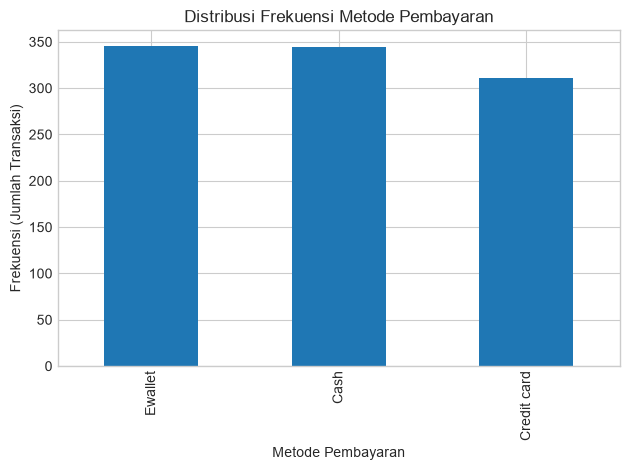

In [16]:
df['Payment'].value_counts().plot(
    kind='bar', title='Distribusi Frekuensi Metode Pembayaran'
)
plt.xlabel('Metode Pembayaran')
plt.ylabel('Frekuensi (Jumlah Transaksi)')
plt.tight_layout()
plt.show()


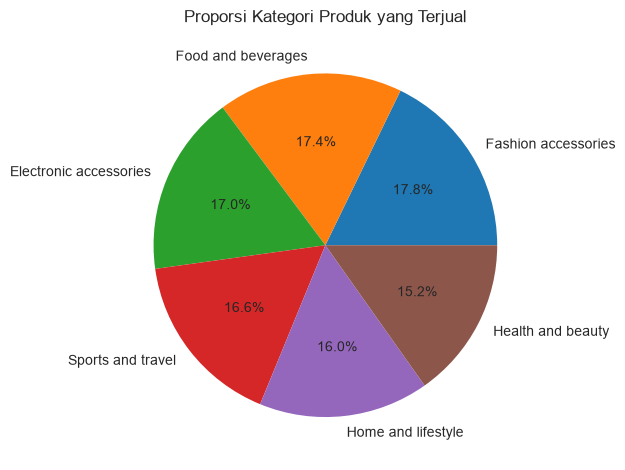

In [17]:
df['Product line'].value_counts().plot(
    kind='pie', autopct='%1.1f%%', title='Proporsi Kategori Produk yang Terjual'
)

plt.ylabel('')
plt.tight_layout()
plt.show()

In [19]:
mean_val = df['Total'].mean()
median_val = df['Total'].median()
mode_val = df['Total'].mode()[0]

print(f'Mean   : {mean_val:.2f}')
print(f'Median : {median_val:.2f}')
print(f'Modus  : {mode_val:.2f}')

Mean   : 322.97
Median : 253.85
Modus  : 87.23


In [20]:
var_val = df['Total'].var(ddof=1)
std_val = df['Total'].std(ddof=1)

print(f'Varians (s^2)        : {var_val:.2f}')
print(f'Standar Deviasi (s)  : {std_val:.2f}')

Varians (s^2)        : 60459.60
Standar Deviasi (s)  : 245.89


C:\Users\Hisyam\AppData\Local\Temp\ipykernel_25408\2557490454.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


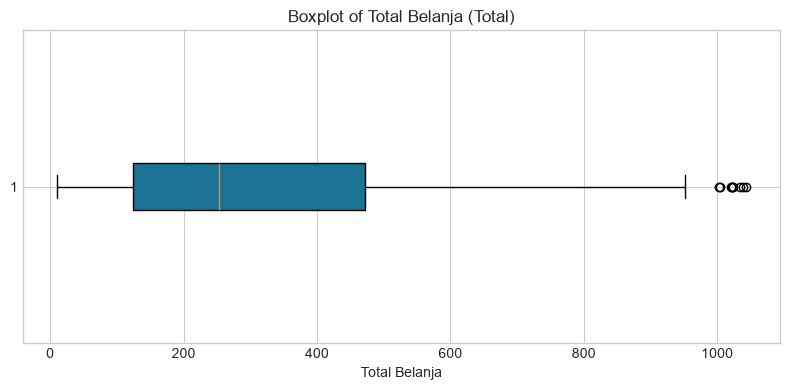

In [22]:
plt.figure(figsize=(8, 4))
plt.boxplot(
    df['Total'],
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor='#1C7293', color='black'),
)
plt.title('Boxplot of Total Belanja (Total)')
plt.xlabel('Total Belanja')
plt.tight_layout()
plt.savefig('total_boxplot.png', dpi=300)
plt.show()

In [23]:
df = pd.read_csv('supermarket_sales_UTS.csv')

crosstab_table = pd.crosstab(df['Customer type'], df['Payment'], margins=True)
print(crosstab_table)

Payment        Cash  Credit card  Ewallet   All
Customer type                                  
Member          168          172      161   501
Normal          176          139      184   499
All             344          311      345  1000


In [24]:
member_df = df[df['Customer type'] == 'Member']

p_ewallet_given_member = (member_df['Payment'] == 'Ewallet').mean()
print(f'P(Ewallet | Member) = {p_ewallet_given_member:.4f}')

P(Ewallet | Member) = 0.3214


In [25]:
p_success = (df['Rating'] >= 8.0).mean()
n = 10
k = 5
p_binomial = stats.binom.pmf(k, n, p_success)
print(f'P(X = {k}) Binomial = {p_binomial:.4f}')

df['Date'] = pd.to_datetime(df['Date'])
daily_low = df[df['Rating'] < 7.0].groupby('Date').size()
date_range = pd.date_range(df['Date'].min(), df['Date'].max())
daily_low = daily_low.reindex(date_range, fill_value=0)
lam = daily_low.mean()

p_poisson = stats.poisson.sf(2, mu=lam)
print(f'P(X > 2) Poisson = {p_poisson:.4f}')

P(X = 5) Binomial = 0.1321
P(X > 2) Poisson = 0.9180


In [26]:
mu = df['Total'].mean()
sigma = df['Total'].std()

val_check = 800
z = (val_check - mu) / sigma
prob_above = 1 - stats.norm.cdf(val_check, mu, sigma)

print(f'Z-score untuk nilai {val_check} : {z:.2f}')
print(f'P(Total > {val_check})             : {prob_above:.4f}')

Z-score untuk nilai 800 : 1.94
P(Total > 800)             : 0.0262


In [27]:
missing_count = df['Total'].isna().sum()
print(f'Jumlah missing value pada kolom Total: {missing_count}')

Jumlah missing value pada kolom Total: 0


In [ ]:
plt.figure(figsize=(8, 4))
count, bins, ignored = plt.hist(var_check, bins=25, density=True, color='#1C7293', edgecolor='white', alpha=0.85)
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 200)
p = stats.norm.pdf(x, mu, sigma)
plt.plot(x, p, color='#E1682C', linewidth=2, label='Kurva Normal Teoretis')
plt.title('Histogram Total Belanja vs Kurva Normal')
plt.xlabel('Total Belanja')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.savefig('normal_dist_total.png', dpi=300)
plt.close()
print("Normal distribution plot saved successfully!")